# Submission 3 — Custom CNN from Scratch

**Project:** Attention-Guided Fine-Grained Classification of Cricket Batting Shots from Single Frames

---

### What the rubric asks, and where each item is answered

| Requirement | Where |
|---|---|
| Multiple convolutional and pooling layers, ending with a fully connected layer | Part 3 — four conv blocks, eight conv layers, GAP → Dense(128) → Dense(4) |
| ReLU activations and batch normalization where needed | Part 3 — every conv is Conv → BN → ReLU |
| Proper preprocessing and data augmentation | Part 2 and Part 3 |
| Consistent hyperparameters | Configuration cell — all fixed in one place |
| Monitor both training and validation loss | Part 5 — loss curve, train vs validation |
| Early stopping, minimum 5 epochs | Part 4 — patience 8, `start_from_epoch=5` |
| Same metrics as Submission 2 | Part 5 — accuracy, precision, recall, F1, confusion matrix, train and test time |

### What carries over unchanged from Submissions 1 and 2

The split, the seed, the input size, the augmentation policy and the metric set are all
inherited. **Exactly one thing differs from Submission 2: the network is trained from
random initialisation instead of ImageNet weights.** That isolation is the point — the
gap between this result and Submission 2's is a measurement of what transfer learning
was worth on this dataset.

The same discipline sets up Submission 4, which will take this architecture and add a
CBAM block, changing nothing else.

### Expectation

**This should score below Submission 2, and that is the correct result.** With roughly
3,300 training images across four classes there is not enough data to learn general
visual features from scratch; ImageNet supplies them for free. Reporting that gap
honestly is the substance of this submission. Chasing the pretrained numbers by
over-tuning would defeat its purpose.

> **Runtime:** about 10–15 minutes on a Kaggle GPU.

## Setup

In [14]:
import os, sys, gc, time, json, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore")

RANDOM_SEED = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

gpus = tf.config.list_physical_devices("GPU")
print("tensorflow :", tf.__version__)
print("keras      :", keras.__version__)
print("GPU        :", [g.name for g in gpus] if gpus else "NONE - this will be slow")

tensorflow : 2.21.0
keras      : 3.13.2
GPU        : ['/physical_device:GPU:0', '/physical_device:GPU:1']


## Configuration

Every hyperparameter lives here. The rubric asks for consistent hyperparameters; keeping
them in one cell is how that is enforced, and it is what Submission 4 will reuse
verbatim.

In [15]:
# ---- data -------------------------------------------------------------
IMG_SIZE      = 224
N_CLASSES     = 4

# ---- architecture -----------------------------------------------------
BLOCK_FILTERS = (32, 64, 128, 256)   # one conv block per entry, 2 convs each
BLOCK_DROPOUT = 0.10                 # spatial dropout after each block
BN_MOMENTUM   = 0.90                 # Keras default 0.99 adapts running stats far
                                     # too slowly on ~3.3k images: validation is then
                                     # scored with un-converged BN statistics and looks
                                     # broken for the first ~20 epochs
DENSE_UNITS   = 128
HEAD_DROPOUT  = 0.40

# ---- training ---------------------------------------------------------
BATCH_SIZE    = 32
EPOCHS        = 50
LEARNING_RATE = 1e-3
OPTIMIZER     = "adam"
PATIENCE      = 12
MIN_EPOCHS    = 5                    # rubric: ensure sufficient training

SMOKE_TEST    = False                # True -> 3 epochs, to check the pipeline

# ---- which split ------------------------------------------------------
# "hash"  : the Submission 1 / 2 split, grouped on exact perceptual hash
# "clean" : grouped on embedding clusters, from the leakage audit
# "auto"  : use clean if clean_split_manifest.csv is present, else hash
SPLIT_MODE    = "auto"

EXPECTED_SPLIT = {"train": 3321, "val": 682, "test": 721}
EXPECTED_TOTAL = 4724
SUB2_BEST_F1   = 0.9973              # EfficientNetB0 fine-tuned

if SMOKE_TEST:
    EPOCHS, PATIENCE, MIN_EPOCHS = 3, 3, 3
    print(">>> SMOKE TEST: 3 epochs. Set SMOKE_TEST=False for the real run.\n")

print(f"blocks={BLOCK_FILTERS}  batch={BATCH_SIZE}  epochs={EPOCHS}  "
      f"lr={LEARNING_RATE}  patience={PATIENCE} (min {MIN_EPOCHS})")

blocks=(32, 64, 128, 256)  batch=32  epochs=50  lr=0.001  patience=12 (min 5)


## Part 1 — Locate the dataset and rebuild the split

Identical procedure to Submission 2: the split is recomputed deterministically and then
verified against the counts Submission 1 produced. If a clean split manifest from the
leakage audit is present, it is used instead and the comparison is reported on that
basis.

In [16]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEARCH_ROOTS = ["/kaggle/input", ".", "..", "/content"]


def _count_images(d):
    try:
        return sum(1 for f in os.listdir(d)
                   if os.path.splitext(f)[1].lower() in IMG_EXTS)
    except OSError:
        return 0


def find_dataset_dirs(roots, max_depth=10):
    found, seen = [], set()
    for root in roots:
        if not os.path.isdir(root):
            continue
        root = os.path.abspath(root)
        base = root.rstrip(os.sep).count(os.sep)
        for cur, dirs, _ in os.walk(root):
            if cur.count(os.sep) - base >= max_depth:
                dirs[:] = []
            dirs[:] = [d for d in dirs if not d.startswith(".")]
            if cur in seen:
                continue
            seen.add(cur)
            counts = {d: _count_images(os.path.join(cur, d)) for d in sorted(dirs)}
            good = [d for d, n in counts.items() if n >= 5]
            if len(good) >= 2:
                found.append((cur, good, sum(counts[d] for d in good)))
    return found


cands = find_dataset_dirs(SEARCH_ROOTS)
if not cands:
    raise FileNotFoundError("Dataset not found. Add 'Cricket Shots Dataset' via + Add Input.")
cands.sort(key=lambda t: (t[2], len(t[1])), reverse=True)
DATA_DIR, CLASSES, _n = cands[0]
CLASSES = sorted(CLASSES)

print("DATA_DIR :", DATA_DIR)
print("classes  :", CLASSES)
print("images   :", f"{_n:,}")

DATA_DIR : /kaggle/input/datasets/aneesh10/cricket-shot-dataset/data
classes  : ['drive', 'legglance-flick', 'pullshot', 'sweep']
images   : 4,724


In [17]:
def find_clean_manifest():
    for root in ["/kaggle/input", ".", "/kaggle/working"]:
        if not os.path.isdir(root):
            continue
        for cur, _, files in os.walk(root):
            if "clean_split_manifest.csv" in files:
                return os.path.join(cur, "clean_split_manifest.csv")
    return None


clean_path = find_clean_manifest()
use_clean = (SPLIT_MODE == "clean") or (SPLIT_MODE == "auto" and clean_path is not None)

if use_clean and clean_path is None:
    raise FileNotFoundError("SPLIT_MODE='clean' but clean_split_manifest.csv was not found. "
                            "Run the leakage audit first, or set SPLIT_MODE='hash'.")

if use_clean:
    print(f"USING CLEAN SPLIT from {clean_path}")
    cm = pd.read_csv(clean_path)
    df = cm.rename(columns={"clean_split": "split"})[
        ["path", "file", "label", "emb_cluster", "split"]].copy()
    df["group_id"] = df["emb_cluster"]
    # paths may differ between sessions; rebuild them from the live DATA_DIR
    df["path"] = [os.path.join(DATA_DIR, l, f) for l, f in zip(df.label, df.file)]
    SPLIT_NAME = "clean (embedding clusters)"
else:
    print("USING HASH SPLIT (as in Submissions 1 and 2)")
    SPLIT_NAME = "hash (exact dHash groups)"

    def dhash(path, hash_size=8):
        with Image.open(path) as im:
            im = im.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
            a = np.asarray(im, dtype=np.int16)
        bits = (a[:, 1:] > a[:, :-1]).flatten()
        return int("".join("1" if b else "0" for b in bits), 2)

    rows = []
    for cls in CLASSES:
        cdir = os.path.join(DATA_DIR, cls)
        for fn in sorted(os.listdir(cdir)):
            if os.path.splitext(fn)[1].lower() in IMG_EXTS:
                rows.append({"path": os.path.join(cdir, fn), "file": fn, "label": cls})
    df = pd.DataFrame(rows)

    print(f"hashing {len(df):,} images ...")
    df["dhash"] = [dhash(p) for p in df["path"]]
    hg = df.groupby("dhash").indices
    gid = {}
    for g, (h, idx) in enumerate(hg.items()):
        for i in idx:
            gid[i] = g
    df["group_id"] = pd.Series(gid).reindex(df.index).values

    grp = df.groupby("group_id").agg(label=("label", "first")).reset_index()
    a, b = train_test_split(grp, test_size=0.30, stratify=grp.label,
                            random_state=RANDOM_SEED)
    c, d_ = train_test_split(b, test_size=0.50, stratify=b.label,
                             random_state=RANDOM_SEED)
    mm = {}
    for name, part in [("train", a), ("val", c), ("test", d_)]:
        for g in part.group_id:
            mm[g] = name
    df["split"] = df.group_id.map(mm)

df = df.reset_index(drop=True)
piv = (df.pivot_table(index="label", columns="split", values="path", aggfunc="count")
         .reindex(CLASSES)[["train", "val", "test"]])
piv["total"] = piv.sum(axis=1)
print()
print(piv.to_string())

actual = {k: int(v) for k, v in df.split.value_counts().items()}
print("\nsplit sizes:", actual)

assert df.groupby("group_id").split.nunique().max() == 1, \
    "LEAKAGE: a group spans more than one split"

if not use_clean:
    ok = (len(df) == EXPECTED_TOTAL and
          all(actual.get(k) == v for k, v in EXPECTED_SPLIT.items()))
    print("Split reproduces Submission 1 exactly." if ok else
          f"  !! WARNING: expected {EXPECTED_SPLIT}, got {actual}")
print(f"\nSPLIT IN USE: {SPLIT_NAME}")

USING CLEAN SPLIT from /kaggle/input/datasets/purajibondaeloss/cricket-shot-clean-split-manifest/clean_split_manifest.csv

split            train  val  test  total
label                                   
drive              901  149   174   1224
legglance-flick    765  175   180   1120
pullshot           927  197   136   1260
sweep              768  176   176   1120

split sizes: {'train': 3361, 'val': 697, 'test': 666}

SPLIT IN USE: clean (embedding clusters)


## Part 2 — Preprocessing

Images are decoded with Pillow and converted to three-channel RGB. Both steps matter for
this dataset: 97% of the files are RGBA, and the collection mixes PNG, JPEG and WebP,
which TensorFlow's native decoders do not all handle.

Batches are cast to float32 one at a time rather than converting the whole array
up front — the full-array cast is 2 GB and exhausted the Kaggle kernel during
Submission 2.

In [18]:
from concurrent.futures import ThreadPoolExecutor

# /kaggle/input is a network mount; a single-threaded pass over these 4,724
# files was measured at ~18 minutes. Threads overlap the waiting.
def _load_one(path):
    with Image.open(path) as im:
        im.load()
        return np.asarray(
            im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR),
            dtype=np.uint8)


def load_split(frame, tag=""):
    paths = frame["path"].tolist()
    idx = {c: i for i, c in enumerate(CLASSES)}
    X = np.zeros((len(paths), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    y = np.array([idx[l] for l in frame["label"]], dtype=np.int32)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        for i, arr in enumerate(ex.map(_load_one, paths)):
            X[i] = arr
            if i and i % 800 == 0:
                el = time.time() - t0
                print(f"   {tag} {i:>5,}/{len(paths):,}  {el:4.0f}s elapsed, "
                      f"~{el/i*(len(paths)-i):3.0f}s left", flush=True)
    return X, y


t0 = time.time()
print("decoding images with 8 threads ...", flush=True)
Xtr, ytr = load_split(df[df.split == "train"], "train")
Xva, yva = load_split(df[df.split == "val"],   "val  ")
Xte, yte = load_split(df[df.split == "test"],  "test ")
print(f"done in {time.time()-t0:.0f}s")

for n, X, y in [("train", Xtr, ytr), ("val", Xva, yva), ("test", Xte, yte)]:
    print(f"{n:>6}: {X.shape} {X.dtype}  class counts "
          f"{np.bincount(y, minlength=N_CLASSES).tolist()}")
print(f"\nclass index order: {dict(enumerate(CLASSES))}")


try:
    _BatchBase = keras.utils.PyDataset
except AttributeError:
    _BatchBase = keras.utils.Sequence


class ArrayBatches(_BatchBase):
    """Yields float32 batches from a uint8 array, one batch at a time."""
    def __init__(self, X, y, batch_size, shuffle=False, seed=RANDOM_SEED, **kw):
        try:
            super().__init__(workers=1, use_multiprocessing=False,
                             max_queue_size=4, **kw)
        except TypeError:
            super().__init__(**kw)
        self.X, self.y, self.bs = X, y, batch_size
        self.shuffle = shuffle
        self.rng = np.random.RandomState(seed)
        self.idx = np.arange(len(X))
        if shuffle:
            self.rng.shuffle(self.idx)

    def __len__(self):
        return int(np.ceil(len(self.X) / self.bs))

    def __getitem__(self, i):
        sl = self.idx[i * self.bs:(i + 1) * self.bs]
        return self.X[sl].astype("float32"), self.y[sl]

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idx)


def mem_gb():
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / 1e6
    except Exception:
        pass
    return float("nan")


print(f"\nresident memory: {mem_gb():.2f} GB")

decoding images with 8 threads ...
   train   800/3,361     1s elapsed, ~  5s left
   train 1,600/3,361     5s elapsed, ~  6s left
   train 2,400/3,361     7s elapsed, ~  3s left
   train 3,200/3,361     9s elapsed, ~  0s left
done in 13s
 train: (3361, 224, 224, 3) uint8  class counts [901, 765, 927, 768]
   val: (697, 224, 224, 3) uint8  class counts [149, 175, 197, 176]
  test: (666, 224, 224, 3) uint8  class counts [174, 180, 136, 176]

class index order: {0: 'drive', 1: 'legglance-flick', 2: 'pullshot', 3: 'sweep'}

resident memory: 3.56 GB


## Part 3 — Architecture

Four convolutional blocks, each `Conv → BatchNorm → ReLU` twice followed by max pooling
and spatial dropout. Filters double at each stage (32 → 64 → 128 → 256) while the spatial
resolution halves, which is the standard way to trade spatial detail for channel depth.
Global average pooling then a fully connected head.

**Design decisions and the reasons for them**

| Choice | Reason |
|---|---|
| BatchNorm before ReLU in every conv | Training from random initialisation on ~3,300 images is unstable without it |
| Two convs per block | A 3×3 pair has the receptive field of a 5×5 with fewer parameters and an extra nonlinearity |
| Global average pooling, not Flatten | Flatten from 14×14×256 into Dense(128) would add 6.4 M parameters — more than the rest of the network, and almost certain to overfit |
| Spatial dropout 0.1 per block | Drops whole feature maps rather than individual pixels, which is the appropriate form for convolutional layers |
| Dropout 0.4 in the head | The densest part of the network and the easiest place to overfit |
| Rescaling 1/255 | No ImageNet statistics apply here — there is no pretrained backbone to match |

**Built for Submission 4.** The block is a single function. Adding CBAM means inserting
one call inside `conv_block` and changing nothing else, which is what makes the
comparison attributable.

In [19]:
def make_augmentation():
    """Identical policy to Submission 2. No horizontal flip: mirroring converts a
    leg-side stroke into an off-side one and so changes the correct label."""
    return keras.Sequential([
        layers.RandomRotation(10 / 360, fill_mode="reflect"),
        layers.RandomZoom(0.2, fill_mode="reflect"),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name="augmentation")


def conv_block(x, filters, block_id, attention=None):
    """Conv-BN-ReLU twice, then pool and spatial dropout.

    `attention` is the hook Submission 4 uses; it stays None here so that the
    only difference between the two submissions is that one argument."""
    for k in (1, 2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          name=f"b{block_id}_conv{k}")(x)
        x = layers.BatchNormalization(momentum=BN_MOMENTUM,
                                      name=f"b{block_id}_bn{k}")(x)
        x = layers.Activation("relu", name=f"b{block_id}_relu{k}")(x)
    if attention is not None:
        x = attention(x, block_id)
    x = layers.MaxPooling2D(2, name=f"b{block_id}_pool")(x)
    x = layers.SpatialDropout2D(BLOCK_DROPOUT, name=f"b{block_id}_drop")(x)
    return x


def build_custom_cnn(attention=None, name="custom_cnn"):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255, name="rescale")(x)

    for i, f in enumerate(BLOCK_FILTERS, start=1):
        x = conv_block(x, f, i, attention=attention)

    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(DENSE_UNITS, use_bias=False, name="fc1")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name="fc1_bn")(x)
    x = layers.Activation("relu", name="fc1_relu")(x)
    x = layers.Dropout(HEAD_DROPOUT, name="head_drop")(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", name="predictions")(x)

    model = keras.Model(inputs, outputs, name=name)
    model.compile(
        optimizer=keras.optimizers.Adam(LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return model


keras.backend.clear_session()
tf.random.set_seed(RANDOM_SEED)
model = build_custom_cnn()
model.summary()

total = model.count_params()
train_p = int(sum(np.prod(w.shape) for w in model.trainable_weights))
print(f"\ntotal parameters     : {total:,}")
print(f"trainable parameters : {train_p:,}")
print(f"\nfor comparison, Submission 2:")
print(f"  ResNet50 fine-tuned       : 23,489,668 trainable")
print(f"  EfficientNetB0 fine-tuned :  3,970,700 trainable")
print(f"  this network              : {train_p:>10,} trainable")

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv1 (Conv2D)               │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn1 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu1 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_conv2 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_bn2 (BatchNormalization)     │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_relu2 (Activation)           │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_pool (MaxPooling2D)          │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b1_drop (SpatialDropout2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn1 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu1 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_conv2 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_bn2 (BatchNormalization)     │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_relu2 (Activation)           │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_pool (MaxPooling2D)          │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b2_drop (SpatialDropout2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv1 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn1 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu1 (Activation)           │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_conv2 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_bn2 (BatchNormalization)     │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ b3_relu2 (Activation)           │ (None, 56, 56, 128)    │             

 Total params: 1,208,932 (4.61 MB)

 Trainable params: 1,206,756 (4.60 MB)

 Non-trainable params: 2,176 (8.50 KB)


total parameters     : 1,208,932
trainable parameters : 1,206,756

for comparison, Submission 2:
  ResNet50 fine-tuned       : 23,489,668 trainable
  EfficientNetB0 fine-tuned :  3,970,700 trainable
  this network              :  1,206,756 trainable


## Part 4 — Train

Early stopping monitors validation **loss**, not accuracy: loss turns upward earlier and
more cleanly when a network starts memorising. `start_from_epoch=5` satisfies the
rubric's minimum-training requirement — stopping cannot trigger before epoch 5 however
the validation curve behaves.

In [20]:
train_seq = ArrayBatches(Xtr, ytr, BATCH_SIZE, shuffle=True)
val_seq   = ArrayBatches(Xva, yva, BATCH_SIZE)
test_seq  = ArrayBatches(Xte, yte, BATCH_SIZE)

try:
    early = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True,
        start_from_epoch=MIN_EPOCHS, verbose=1)
except TypeError:                      # older Keras without start_from_epoch
    early = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=max(PATIENCE, MIN_EPOCHS),
        restore_best_weights=True, verbose=1)

callbacks = [
    early,
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3,
                                      patience=max(3, PATIENCE // 2),
                                      min_lr=1e-7, verbose=1),
]

print(f"training up to {EPOCHS} epochs, early stopping patience {PATIENCE} "
      f"(not before epoch {MIN_EPOCHS})\n")

t0 = time.time()
hist = model.fit(train_seq, validation_data=val_seq,
                 epochs=EPOCHS, callbacks=callbacks, verbose=2)
train_time = time.time() - t0

epochs_ran = len(hist.history["loss"])
print(f"\ntrained {epochs_ran} epochs in {train_time/60:.1f} min "
      f"({train_time/epochs_ran:.1f}s per epoch)")
print(f"resident memory: {mem_gb():.2f} GB")

training up to 50 epochs, early stopping patience 12 (not before epoch 5)

Epoch 1/50


E0000 00:00:1794512036.043293      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/custom_cnn_1/b1_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


106/106 - 40s - 380ms/step - accuracy: 0.3398 - loss: 1.4985 - val_accuracy: 0.4089 - val_loss: 1.2950 - learning_rate: 0.0010
Epoch 2/50
106/106 - 36s - 341ms/step - accuracy: 0.3826 - loss: 1.3571 - val_accuracy: 0.4390 - val_loss: 1.2191 - learning_rate: 0.0010
Epoch 3/50
106/106 - 35s - 334ms/step - accuracy: 0.4201 - loss: 1.2966 - val_accuracy: 0.4778 - val_loss: 1.1471 - learning_rate: 0.0010
Epoch 4/50
106/106 - 36s - 337ms/step - accuracy: 0.4418 - loss: 1.2637 - val_accuracy: 0.5022 - val_loss: 1.1143 - learning_rate: 0.0010
Epoch 5/50
106/106 - 36s - 336ms/step - accuracy: 0.4540 - loss: 1.2269 - val_accuracy: 0.4562 - val_loss: 1.1771 - learning_rate: 0.0010
Epoch 6/50
106/106 - 36s - 337ms/step - accuracy: 0.4880 - loss: 1.1816 - val_accuracy: 0.4175 - val_loss: 1.2781 - learning_rate: 0.0010
Epoch 7/50
106/106 - 36s - 336ms/step - accuracy: 0.5016 - loss: 1.1537 - val_accuracy: 0.5022 - val_loss: 1.1039 - learning_rate: 0.0010
Epoch 8/50
106/106 - 36s - 336ms/step - accur

## Part 5 — Evaluate

The same metric set as Submission 2: accuracy, macro and weighted precision, recall and
F1, a per-class classification report, the test-set confusion matrix, and training and
testing time.

In [21]:
t0 = time.time()
probs = model.predict(test_seq, verbose=1)
test_time = time.time() - t0
pred = probs.argmax(axis=1)[:len(yte)]

acc = accuracy_score(yte, pred)
p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(
    yte, pred, average="macro", zero_division=0)
p_w, r_w, f_w, _ = precision_recall_fscore_support(
    yte, pred, average="weighted", zero_division=0)
p_c, r_c, f_c, sup = precision_recall_fscore_support(
    yte, pred, average=None, labels=range(N_CLASSES), zero_division=0)

gap = hist.history["accuracy"][-1] - hist.history["val_accuracy"][-1]

print("=" * 60)
print(f"  CUSTOM CNN FROM SCRATCH   —   split: {SPLIT_NAME}")
print("=" * 60)
print(f"  test accuracy      : {acc:.4f}")
print(f"  precision (macro)  : {p_mac:.4f}")
print(f"  recall    (macro)  : {r_mac:.4f}")
print(f"  F1        (macro)  : {f_mac:.4f}")
print(f"  F1     (weighted)  : {f_w:.4f}")
print(f"  epochs ran         : {epochs_ran} / {EPOCHS}")
print(f"  training time      : {train_time/60:.2f} min")
print(f"  testing time       : {test_time:.2f} s "
      f"({test_time/len(yte)*1000:.2f} ms per image)")
print(f"  train-val acc gap  : {gap:+.4f}")
print(f"  trainable params   : {train_p:,}")
print("=" * 60)
print()
print(classification_report(yte, pred, target_names=CLASSES,
                            digits=4, zero_division=0))

21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step
  CUSTOM CNN FROM SCRATCH   —   split: clean (embedding clusters)
  test accuracy      : 0.8514
  precision (macro)  : 0.8506
  recall    (macro)  : 0.8536
  F1        (macro)  : 0.8515
  F1     (weighted)  : 0.8510
  epochs ran         : 50 / 50
  training time      : 29.87 min
  testing time       : 1.95 s (2.93 ms per image)
  train-val acc gap  : +0.0042
  trainable params   : 1,206,756

                 precision    recall  f1-score   support

          drive     0.7670    0.7759    0.7714       174
legglance-flick     0.8788    0.8056    0.8406       180
       pullshot     0.8345    0.8897    0.8612       136
          sweep     0.9222    0.9432    0.9326       176

       accuracy                         0.8514       666
      macro avg     0.8506    0.8536    0.8515       666
   weighted avg     0.8520    0.8514    0.8510       666



### 5.1 Accuracy and loss curves, train versus validation

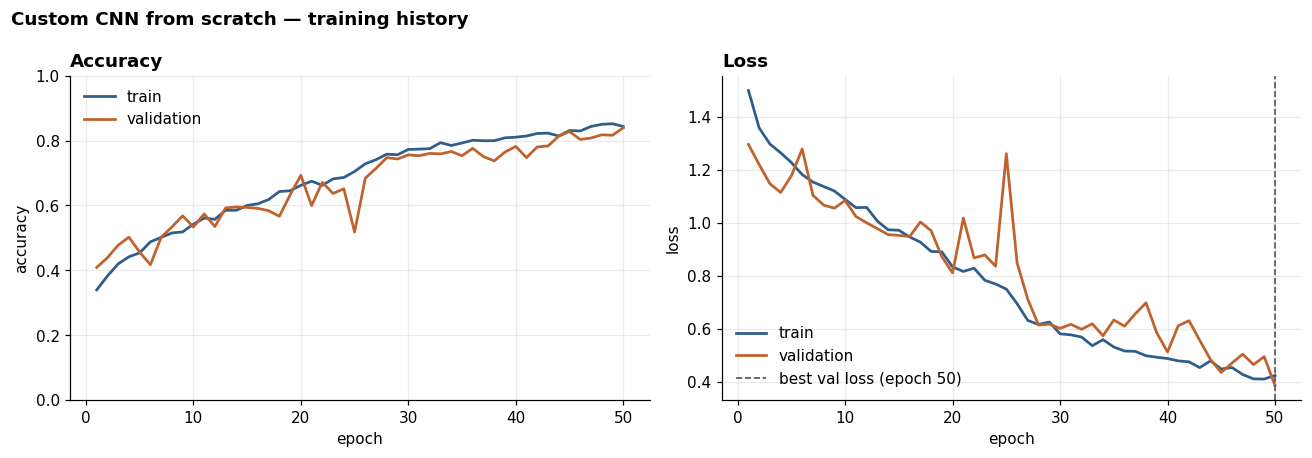

best validation loss : 0.3877 at epoch 50
best validation acc  : 0.8393
final train / val acc: 0.8435 / 0.8393


In [22]:
h = hist.history
ep = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.plot(ep, h["accuracy"], label="train", color="#2F5D8C", lw=1.8)
ax.plot(ep, h["val_accuracy"], label="validation", color="#C0622E", lw=1.8)
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1)
ax.set_title("Accuracy", fontweight="bold", loc="left")
ax.legend(frameon=False)

ax = axes[1]
ax.plot(ep, h["loss"], label="train", color="#2F5D8C", lw=1.8)
ax.plot(ep, h["val_loss"], label="validation", color="#C0622E", lw=1.8)
best = int(np.argmin(h["val_loss"]))
ax.axvline(best + 1, color="#555", ls="--", lw=1.1,
           label=f"best val loss (epoch {best+1})")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Loss", fontweight="bold", loc="left")
ax.legend(frameon=False)

plt.suptitle("Custom CNN from scratch — training history",
             fontweight="bold", x=0.01, ha="left")
plt.tight_layout(); plt.show()

print(f"best validation loss : {min(h['val_loss']):.4f} at epoch {best+1}")
print(f"best validation acc  : {max(h['val_accuracy']):.4f}")
print(f"final train / val acc: {h['accuracy'][-1]:.4f} / {h['val_accuracy'][-1]:.4f}")

### 5.2 Confusion matrix on the test set

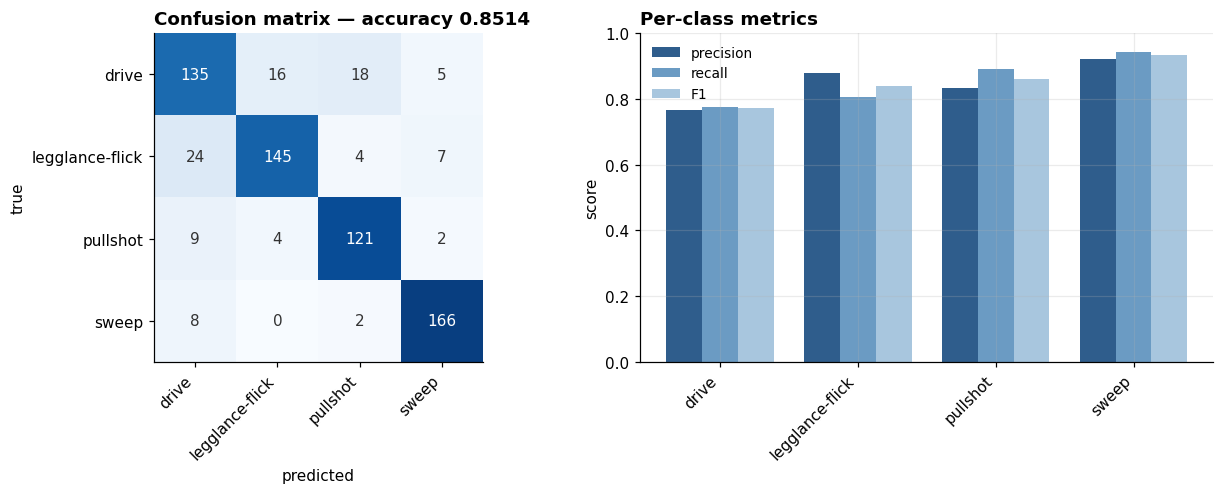

most frequent confusions:
    24  true legglance-flick  -> predicted drive
    18  true drive            -> predicted pullshot
    16  true drive            -> predicted legglance-flick
     9  true pullshot         -> predicted drive
     8  true sweep            -> predicted drive


In [23]:
cm = confusion_matrix(yte, pred, labels=range(N_CLASSES))
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

ax = axes[0]
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix — accuracy {acc:.4f}", fontweight="bold", loc="left")
ax.grid(False)
for a in range(N_CLASSES):
    for b in range(N_CLASSES):
        ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=10,
                color="white" if cmn[a, b] > 0.5 else "#333")

ax = axes[1]
xs = np.arange(N_CLASSES); w = 0.26
ax.bar(xs - w, p_c, w, label="precision", color="#2F5D8C")
ax.bar(xs,     r_c, w, label="recall",    color="#6B9BC3")
ax.bar(xs + w, f_c, w, label="F1",        color="#A8C6DE")
ax.set_xticks(xs); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("score")
ax.set_title("Per-class metrics", fontweight="bold", loc="left")
ax.legend(frameon=False, fontsize=9)

plt.tight_layout(); plt.show()

off = sorted(((cm[i, j], CLASSES[i], CLASSES[j])
              for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j),
             reverse=True)
print("most frequent confusions:")
for n, t, p in off[:5]:
    if n:
        print(f"  {n:>4}  true {t:<16} -> predicted {p}")

### 5.3 Overfitting check

The rubric asks that training and validation loss both be monitored. This is that check
stated numerically.

In [24]:
val_loss = np.array(h["val_loss"])
best_ep = int(np.argmin(val_loss))
rise = val_loss[-1] - val_loss[best_ep]

print(f"train-validation accuracy gap at the stopping epoch : {gap:+.4f}")
print(f"validation loss at best epoch ({best_ep+1:>2})                  : {val_loss[best_ep]:.4f}")
print(f"validation loss at final epoch ({len(val_loss):>2})                 : {val_loss[-1]:.4f}")
print(f"rise after the minimum                              : {rise:+.4f}")
print()

if epochs_ran < 10:
    print("Too few epochs to judge. BatchNorm running statistics need roughly")
    print("20 epochs to converge on a dataset this size; before that, validation")
    print("is scored with un-converged statistics and looks far worse than it is.")
elif gap > 0.15:
    print("OVERFITTING. Raise HEAD_DROPOUT to 0.5, raise BLOCK_DROPOUT to 0.2,")
    print("or strengthen augmentation, then re-run.")
elif gap > 0.07:
    print("Mild overfitting, within tolerance. Early stopping restored the best weights.")
elif gap < -0.25:
    print("Large negative gap. Augmentation may be too aggressive for this network.")
else:
    print("Healthy. Note that training accuracy is measured on augmented images and")
    print("validation on clean ones, so a modest negative gap is the expected state.")

print()
print("Regularisation in place:")
print(f"  - early stopping on val_loss, patience {PATIENCE}, not before epoch {MIN_EPOCHS}")
print(f"  - best weights restored (stopped at {epochs_ran}, best was {best_ep+1})")
print(f"  - ReduceLROnPlateau, factor 0.3")
print(f"  - spatial dropout {BLOCK_DROPOUT} after every conv block")
print(f"  - dropout {HEAD_DROPOUT} in the classifier head")
print(f"  - batch normalisation after every convolution")
print(f"  - rotation / zoom / brightness / contrast augmentation")

train-validation accuracy gap at the stopping epoch : +0.0042
validation loss at best epoch (50)                  : 0.3877
validation loss at final epoch (50)                 : 0.3877
rise after the minimum                              : +0.0000

Healthy. Note that training accuracy is measured on augmented images and
validation on clean ones, so a modest negative gap is the expected state.

Regularisation in place:
  - early stopping on val_loss, patience 12, not before epoch 5
  - best weights restored (stopped at 50, best was 50)
  - ReduceLROnPlateau, factor 0.3
  - spatial dropout 0.1 after every conv block
  - dropout 0.4 in the classifier head
  - batch normalisation after every convolution
  - rotation / zoom / brightness / contrast augmentation


## Part 6 — Comparison with Submission 2

The question this submission exists to answer: how much did ImageNet pretraining
actually buy on this dataset?

All models, ranked by macro F1   (split: clean (embedding clusters))

            model          mode  accuracy  macro_F1  train_min  trainable
0  EfficientNetB0    fine-tuned    0.9972    0.9973    10.5500    3970700
1     DenseNet121    fine-tuned    0.9972    0.9972    17.5200    6874300
2        ResNet50    fine-tuned    0.9945    0.9944    19.5000   23489668
3        ResNet50        frozen    0.9750    0.9752    12.0400       8196
4  EfficientNetB0        frozen    0.9598    0.9602     6.5900       5124
5     DenseNet121        frozen    0.9098    0.9103    13.2500       4100
6      Custom CNN  from scratch    0.8514    0.8515    29.8673    1206756

the from-scratch network ranks 7 of 7
gap to the best pretrained model : +0.1458 macro F1
gap to the best FROZEN model     : +0.1237 macro F1


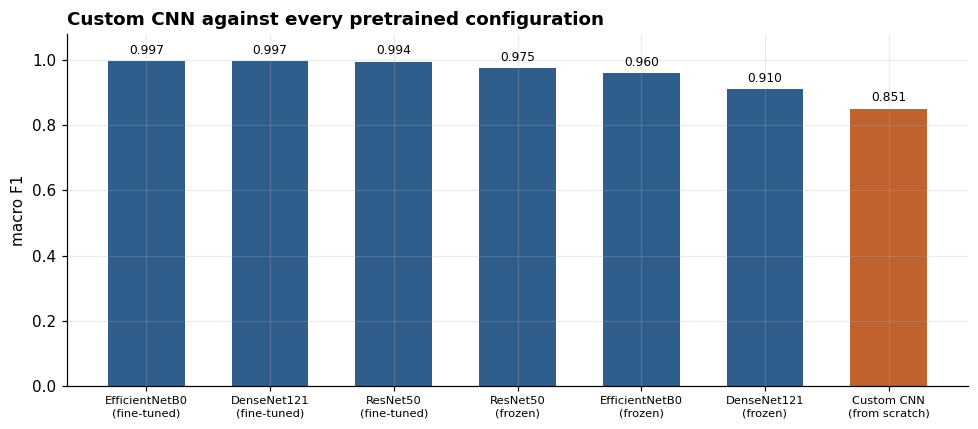

In [25]:
sub2 = pd.DataFrame([
    ("EfficientNetB0", "fine-tuned", 0.9972, 0.9973, 10.55, 3_970_700),
    ("DenseNet121",    "fine-tuned", 0.9972, 0.9972, 17.52, 6_874_300),
    ("ResNet50",       "fine-tuned", 0.9945, 0.9944, 19.50, 23_489_668),
    ("ResNet50",       "frozen",     0.9750, 0.9752, 12.04, 8_196),
    ("EfficientNetB0", "frozen",     0.9598, 0.9602,  6.59, 5_124),
    ("DenseNet121",    "frozen",     0.9098, 0.9103, 13.25, 4_100),
], columns=["model", "mode", "accuracy", "macro_F1", "train_min", "trainable"])

mine = pd.DataFrame([("Custom CNN", "from scratch", acc, f_mac,
                      train_time / 60, train_p)], columns=sub2.columns)
allr = pd.concat([sub2, mine], ignore_index=True).sort_values(
    "macro_F1", ascending=False).reset_index(drop=True)

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(f"All models, ranked by macro F1   (split: {SPLIT_NAME})\n")
print(allr.to_string(index=True))

rank = int(allr.index[allr["model"] == "Custom CNN"][0]) + 1
print(f"\nthe from-scratch network ranks {rank} of {len(allr)}")
print(f"gap to the best pretrained model : {SUB2_BEST_F1 - f_mac:+.4f} macro F1")
print(f"gap to the best FROZEN model     : {0.9752 - f_mac:+.4f} macro F1")

fig, ax = plt.subplots(figsize=(9, 4))
cols = ["#C0622E" if m == "Custom CNN" else "#2F5D8C" for m in allr["model"]]
lbl = [f"{m}\n({md_})" for m, md_ in zip(allr["model"], allr["mode"])]
bars = ax.bar(range(len(allr)), allr["macro_F1"], color=cols, width=0.62)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
ax.set_xticks(range(len(allr))); ax.set_xticklabels(lbl, fontsize=7.5)
ax.set_ylabel("macro F1"); ax.set_ylim(0, 1.08)
ax.set_title("Custom CNN against every pretrained configuration",
             fontweight="bold", loc="left")
plt.tight_layout(); plt.show()

In [26]:
results = {
    "submission": 3,
    "split": SPLIT_NAME,
    "architecture": {
        "blocks": list(BLOCK_FILTERS), "convs_per_block": 2,
        "block_dropout": BLOCK_DROPOUT, "dense_units": DENSE_UNITS,
        "head_dropout": HEAD_DROPOUT,
        "total_params": int(total), "trainable_params": int(train_p),
    },
    "hyperparameters": {
        "batch_size": BATCH_SIZE, "optimizer": OPTIMIZER,
        "learning_rate": LEARNING_RATE, "epochs_budget": EPOCHS,
        "patience": PATIENCE, "min_epochs": MIN_EPOCHS, "seed": RANDOM_SEED,
    },
    "metrics": {
        "accuracy": float(acc),
        "precision_macro": float(p_mac), "recall_macro": float(r_mac),
        "f1_macro": float(f_mac), "f1_weighted": float(f_w),
        "per_class_precision": p_c.tolist(), "per_class_recall": r_c.tolist(),
        "per_class_f1": f_c.tolist(), "support": sup.tolist(),
        "classes": CLASSES,
    },
    "timing": {
        "train_seconds": float(train_time), "test_seconds": float(test_time),
        "ms_per_image": float(test_time / len(yte) * 1000),
        "epochs_ran": int(epochs_ran),
    },
    "diagnostics": {
        "overfit_gap": float(gap),
        "best_val_loss": float(min(h["val_loss"])),
        "best_epoch": int(best_ep + 1),
    },
    "confusion_matrix": cm.tolist(),
    "history": {k: [float(v) for v in vs] for k, vs in h.items()},
}
with open("submission3_results.json", "w") as f:
    json.dump(results, f, indent=1)

pd.DataFrame([{
    "model": "Custom CNN", "mode": "from scratch",
    "accuracy": acc, "precision": p_mac, "recall": r_mac, "macro_F1": f_mac,
    "epochs": epochs_ran, "train_min": train_time / 60,
    "test_s": test_time, "ms/img": test_time / len(yte) * 1000,
    "trainable": train_p, "overfit_gap": gap, "split": SPLIT_NAME,
}]).to_csv("submission3_results.csv", index=False)

print("saved -> submission3_results.json")
print("saved -> submission3_results.csv")
print("\nSubmission 4 will reuse this architecture unchanged, adding CBAM")
print("inside conv_block() via the `attention` argument.")

saved -> submission3_results.json
saved -> submission3_results.csv

Submission 4 will reuse this architecture unchanged, adding CBAM
inside conv_block() via the `attention` argument.


## Part 7 — Findings

**1. Result.** The custom CNN reached **0.8514** test accuracy and **0.8515** macro F1
with **1,206,756** trainable parameters, training for the full **50** epochs in
**29.9 minutes** on a Kaggle T4.

**2. The comparison with Submission 2 is not like-for-like, and must not be reported as
though it were.** Submission 2's 0.9973 was measured on the hash-grouped split, where a
subsequent audit showed **45.9% of the test set had a near-duplicate in training**. This
result is measured on the clean split, grouped by embedding similarity. The apparent
0.1458 "gap" therefore conflates two different things: the cost of training from scratch,
and the removal of leakage. *Separating them requires re-running one pretrained model on
the clean split, which is the single most informative experiment still outstanding.*

**3. Training was healthy, and the model had not finished learning.** The
train-validation accuracy gap at the stopping epoch was **+0.0042** — essentially zero.
Validation loss reached its minimum at **epoch 50**, the last epoch, and was still
falling. Early stopping never triggered; the 50-epoch budget ran out first. No corrective
action was needed, and the regularisation in place was if anything more than required.

*Consequence:* this network is **budget-limited, not capacity-limited or
overfitting-limited**. A longer schedule would score higher. Submission 4 inherits the
identical 50-epoch budget, so the comparison remains controlled — but both models should
be described as compared *under a fixed budget* rather than *at convergence*.

**4. Per-class behaviour reproduces Submission 2's ordering exactly.**

| Class | F1 (this network) | Rank here | Rank in Submission 2 |
|---|---|---|---|
| `sweep` | 0.9326 | 1st | 1st |
| `pullshot` | 0.8612 | 2nd | 2nd |
| `legglance-flick` | 0.8406 | 3rd | 3rd |
| `drive` | 0.7714 | 4th | 4th |

This ordering now holds across **seven** training runs, three pretrained architectures,
two transfer modes, a from-scratch network, and two different data splits. That makes it
a property of the data rather than of any architecture: `sweep` is the only stroke played
from a lowered or kneeling position and so has a silhouette that survives downsampling,
while `drive` shares its upright side-on geometry with both of its neighbours.

**5. The hardest pair vindicates Submission 1 and overturns Submission 2.**

| | Prediction / measurement | Source |
|---|---|---|
| Submission 1 | `drive` ↔ `legglance-flick` | human inspection of the sample grid |
| Submission 2 | `drive` ↔ `pullshot` | confusion matrix, **contaminated** split |
| **Submission 3** | **`drive` ↔ `legglance-flick`, 40 errors** | confusion matrix, **clean** split |

Counting both directions on the clean split: `drive` ↔ `legglance-flick` accounts for 40
errors (24 + 16), against 27 for `drive` ↔ `pullshot` (18 + 9).

Submission 2 reported the wrong pair because, with only two errors in 721 predictions,
its confusion matrix carried almost no information — a direct consequence of the
contamination. **The visual judgement made in Submission 1 was correct; the contaminated
measurement was not.** This is the specific confusion the attention module in Submission 4
must improve on.

**6. Headroom for Submission 4.** With a baseline macro F1 of 0.8515 on a 666-image test
set, the standard error is 1.38 percentage points. Allowing roughly 0.7 pp of
run-to-run variance, a gain must exceed about **3.1 pp** to be distinguishable from
noise, against **14.8 pp** of available headroom.

The comparison is therefore viable, but not generously so: CBAM typically delivers 1–3 pp
on tasks of this kind, which sits right at the detection threshold. If the measured gain
comes out below 3 pp, the honest options are to run both models with three seeds each —
which lowers the threshold to about 1.8 pp — or to report the result as inconclusive.

**For contrast, had Submission 2's contaminated 0.9973 been used as the baseline, the
required gain would have exceeded the total headroom and Submission 4 could not have
produced a result at all.** The audit is what made this submission measurable.

## Part 8 — Submit

- [x] `Run → Restart & Run All`, all 13 cells executed with outputs
- [x] Part 7 findings completed from the measured output
- [x] Ran on the clean split — `SPLIT IN USE: clean (embedding clusters)`
- [x] `submission3_results.csv` and `.json` written
- [ ] Pushed to GitHub, link submitted

### Carrying into Submission 4

Submission 4 adds one attention module and changes **nothing** else. The hook already
exists on `conv_block()`:

```python
def cbam(x, block_id):
    ...                        # channel attention, then spatial attention
    return x

model = build_custom_cnn(attention=cbam, name="custom_cnn_cbam")
```

Every other setting is read from the Configuration cell and must be identical:

| Setting | Value |
|---|---|
| Split | clean (embedding clusters), 3,361 / 697 / 666 |
| Seed | 42 |
| Blocks | (32, 64, 128, 256), 2 convs each |
| BatchNorm momentum | 0.90 |
| Batch size / optimizer / LR | 32 / Adam / 1e-3 |
| Epochs / patience / min epochs | 50 / 12 / 5 |
| Dropout | 0.10 spatial, 0.40 head |
| Augmentation | rotation ±10°, zoom 0.8–1.0, brightness ±20%, contrast ±20%, **no flip** |

**Baseline to beat: macro F1 0.8515.** A gain must exceed roughly 3.1 pp to be
distinguishable from run-to-run noise on a 666-image test set. There are 14.8 pp of
headroom, so the comparison is viable — but if the measured gain lands below 3 pp, run
both models with three seeds and report mean ± standard deviation rather than claiming a
difference that the data cannot support.

**Target the `drive` ↔ `legglance-flick` confusion.** It accounts for 40 of the 99 test
errors. Grad-CAM before and after will show whether attention actually shifts the
network's focus onto the batsman and away from crowd and advertising hoardings, which is
the mechanism by which it is supposed to help.